# Thí nghiệm 3: phân bố, độ ổn định và bất định

Viết lại ý tưởng phân bố nhiều lần chạy; **không** dùng “sai số so với optimum” khi chưa xác minh.


**Cách chạy:** từ root cài `python -m pip install -r requirements.txt`, mở
`jupyter notebook`, chọn kernel/interpreter `.venv` vừa cài rồi **Restart Kernel & Run All**.
Trong VS Code, dùng **Select Kernel → Python Environments → .venv**. Nếu import lỗi,
kiểm tra kernel; không sửa sys.path. Notebook nhận diện root khi mở từ root hoặc `Experiment/`.

Quick mặc định dùng 5 seed cố định, run count và objective budget hữu hạn; Full là opt-in 25 seed.
Mỗi run có cooperative time cap và tổng solver time cap (không phải hard real-time).
Không ghi raw output ra file hay lặp đến khi đạt một nghiệm mong muốn. Chạy lại từ đầu để reset biến.
Chi phí là đơn vị của ma trận, không mặc định km. Cả 7 file có `known_optimum=None`;
không dùng hậu tố filename làm optimum/gap đã chứng minh.


In [1]:
from pathlib import Path
from dataclasses import replace
import json
import math
import platform
import statistics
from time import perf_counter
from IPython import get_ipython
from IPython.display import display, Markdown
import matplotlib.pyplot as plt

from ga_eho_tsp import __version__
from ga_eho_tsp.algorithms.ga import solve
from ga_eho_tsp.data.matrix_loader import load_matrix
from ga_eho_tsp.domain.models import GAConfig
from ga_eho_tsp.domain.objective import validate_route

get_ipython().run_line_magic('matplotlib', 'inline')
plt.rcParams.update({'figure.dpi': 85, 'font.size': 9})
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'pyproject.toml').is_file() and (p / 'data/legacy').is_dir()), None)
if ROOT is None:
    raise RuntimeError('Hãy mở Jupyter từ root dự án hoặc Experiment/.')

MODE = 'QUICK'  # Đổi thành FULL rồi Restart Kernel & Run All để dùng 25 seed.
assert MODE in {'QUICK', 'FULL'}
SEEDS = [11, 23, 37, 53, 71] if MODE == 'QUICK' else list(range(101, 126))
SOLVER_SECONDS_LIMIT = 120.0 if MODE == 'QUICK' else 600.0
MAX_RUNS = 150 if MODE == 'QUICK' else 1200
RUN_COUNT, SOLVER_SECONDS = 0, 0.0
SESSION_START = perf_counter()

def checked_solve(problem, config):
    global RUN_COUNT, SOLVER_SECONDS
    remaining = SOLVER_SECONDS_LIMIT - SOLVER_SECONDS
    if RUN_COUNT >= MAX_RUNS or remaining <= 0:
        raise RuntimeError('Vượt hạn mức notebook; không coi batch thiếu là đã hoàn thành.')
    config = replace(config, time_limit_seconds=min(5.0 if MODE == 'QUICK' else 15.0, remaining))
    result = solve(problem, config)
    RUN_COUNT += 1
    SOLVER_SECONDS += result.elapsed_seconds
    validate_route(result.best_route, problem.dimension)
    independent_cost = sum(problem.distance_matrix[result.best_route[i]][
        result.best_route[(i + 1) % problem.dimension]] for i in range(problem.dimension))
    assert math.isclose(result.best_distance, independent_cost, rel_tol=1e-12, abs_tol=1e-9)
    assert result.is_valid and result.evaluations <= config.max_evaluations
    assert result.history[0].iteration == 0
    assert result.history[-1].evaluations == result.evaluations
    assert all(b.best_so_far <= a.best_so_far for a, b in zip(result.history, result.history[1:]))
    assert result.metadata['local_search_full_evaluations'] <= result.evaluations
    return result

def show_table(headers, rows):
    text = '| ' + ' | '.join(headers) + ' |\n'
    text += '| ' + ' | '.join(['---'] * len(headers)) + ' |\n'
    text += '\n'.join('| ' + ' | '.join(map(str, row)) + ' |' for row in rows)
    display(Markdown(text))

print(f'Python {platform.python_version()} | ga_eho_tsp {__version__} | {MODE} | seeds={SEEDS}')


Python 3.11.9 | ga_eho_tsp 0.2.0 | QUICK | seeds=[11, 23, 37, 53, 71]


## Mục tiêu, giả thuyết và thiết kế
Khi n tăng, phân bố nghiệm có thể rộng hơn; 5 seed Quick chỉ mô tả mẫu, không đủ suy luận chắc chắn.
Chạy hữu hạn trên3/6/15/26/42/48city. Cùng control random/tournament/OX/inversion và budget mỗi run.
`best_observed` là min trong **mẫu đang chạy**, có thể thay đổi nếu thêm seed.
Excess = distance−best_observed, không gọi là sai số tối ưu toàn cục.


In [2]:
DATASETS = ['03Cities-6.txt', '06Cities-1248.txt', '15Cities-1194.txt',
            '26Cities-937.txt', '42Cities-699.txt', '48Cities-33523.txt']
BUDGET = 4000 if MODE == 'QUICK' else 12000
BASE = GAConfig(population_size=40 if MODE == 'QUICK' else 80,
                generations=4000, max_iterations=4000, max_evaluations=BUDGET)
problems = {name: load_matrix(ROOT/'data/legacy'/name) for name in DATASETS}
print(f'{len(DATASETS)} datasets × {len(SEEDS)} seeds; budget/run={BUDGET}; aggregate solver cap={SOLVER_SECONDS_LIMIT}s')


6 datasets × 5 seeds; budget/run=4000; aggregate solver cap=120.0s


In [3]:
runs_by_dataset = {}
for name, problem in problems.items():
    assert problem.known_optimum is None
    runs_by_dataset[name] = [checked_solve(problem, replace(BASE, seed=seed)) for seed in SEEDS]


## Thống kê mẫu
Sample std dùng mẫu số runs−1. Tỉ lệ hit = số run có cost bằng min mẫu / số runs;
đây **không phải** xác suất đạt tối ưu thật. Relative excess chỉ tính nếu min mẫu>0.


In [4]:
distribution_summary = {}
rows = []
for name, runs in runs_by_dataset.items():
    values = [r.best_distance for r in runs]
    observed = min(values)
    hit_rate = sum(value == observed for value in values)/len(values)
    summary = {'n': problems[name].dimension, 'runs': len(runs), 'min': observed,
               'mean': statistics.mean(values), 'median': statistics.median(values),
               'max': max(values), 'std': statistics.stdev(values), 'observed_hit_rate': hit_rate,
               'runtime_mean': statistics.mean(r.elapsed_seconds for r in runs),
               'evaluations_min': min(r.evaluations for r in runs),
               'evaluations_max': max(r.evaluations for r in runs)}
    distribution_summary[name] = summary
    rows.append([summary['n'], summary['runs'], f"{observed:g}", f"{summary['mean']:.2f}",
        f"{summary['median']:.2f}", f"{summary['max']:g}", f"{summary['std']:.2f}",
        f'{100*hit_rate:.0f}%', f"{summary['runtime_mean']:.4f}",
        f"{summary['evaluations_min']}–{summary['evaluations_max']}"])
show_table(['n', 'Runs', 'Min observed', 'Mean', 'Median', 'Max', 'Sample std',
            'Hit observed min', 'Runtime mean(s)', 'Actual evaluations'], rows)


| n | Runs | Min observed | Mean | Median | Max | Sample std | Hit observed min | Runtime mean(s) | Actual evaluations |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 3 | 5 | 6 | 6.00 | 6.00 | 6 | 0.00 | 100% | 0.0348 | 4000–4000 |
| 6 | 5 | 1248 | 1248.00 | 1248.00 | 1248 | 0.00 | 100% | 0.0408 | 4000–4000 |
| 15 | 5 | 1194 | 1200.20 | 1194.00 | 1225 | 13.86 | 80% | 0.0630 | 4000–4000 |
| 26 | 5 | 969 | 1046.00 | 1034.00 | 1186 | 82.85 | 20% | 0.0571 | 4000–4000 |
| 42 | 5 | 1102 | 1151.60 | 1133.00 | 1211 | 49.75 | 20% | 0.0733 | 4000–4000 |
| 48 | 5 | 51215 | 55404.60 | 55339.00 | 59638 | 3031.79 | 20% | 0.0775 | 4000–4000 |

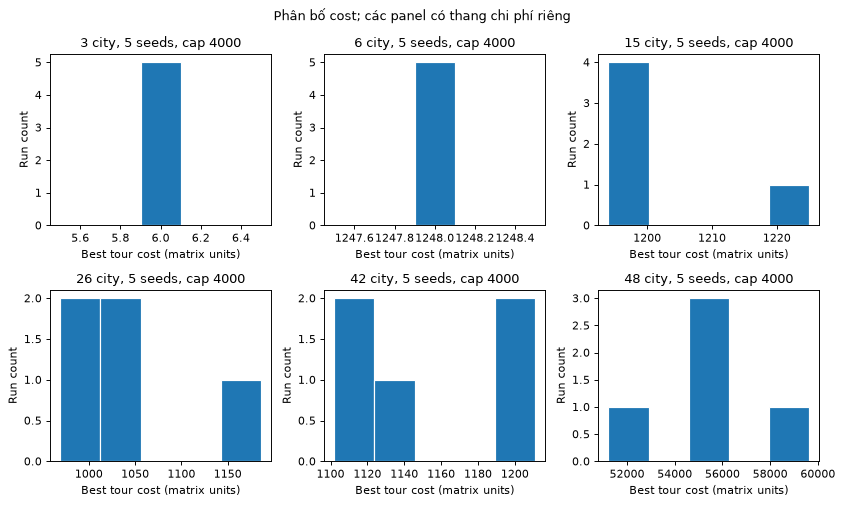

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(10, 6))
for ax, (name, runs) in zip(axes.flat, runs_by_dataset.items()):
    values = [r.best_distance for r in runs]
    ax.hist(values, bins=min(8, len(values)), edgecolor='white')
    ax.set(title=f'{problems[name].dimension} city, {len(values)} seeds, cap {BUDGET}',
           xlabel='Best tour cost (matrix units)', ylabel='Run count')
fig.suptitle('Phân bố cost; các panel có thang chi phí riêng', fontsize=11)
fig.tight_layout(); plt.show(); plt.close(fig)


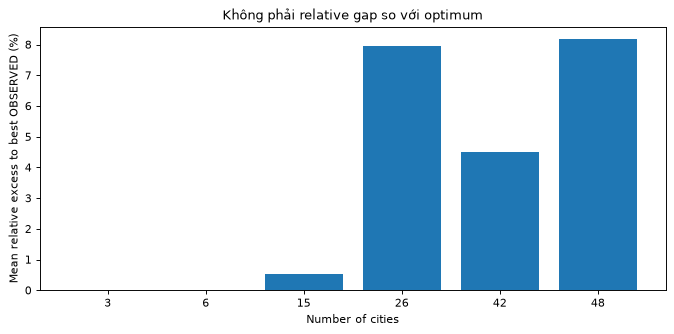

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
mean_excess = []
for name, runs in runs_by_dataset.items():
    observed = distribution_summary[name]['min']
    excess = [100*(r.best_distance-observed)/observed if observed>0 else 0.0 for r in runs]
    mean_excess.append(statistics.mean(excess))
ax.bar([str(problems[n].dimension) for n in DATASETS], mean_excess)
ax.set(xlabel='Number of cities', ylabel='Mean relative excess to best OBSERVED (%)',
       title='Không phải relative gap so với optimum')
fig.tight_layout(); plt.show(); plt.close(fig)


## Kiểm chứng offline độc lập cho n≤6
Chỉ liệt kê tối đa5! tail permutations để kiểm chứng hai file nhỏ; không thêm solver thứ ba vào package.
Chi phí dưới tính trực tiếp từ matrix và cạnh đóng vòng, không dùng GA hay name hint để xác định min.
Registry vẫn `known_optimum=None`: kết quả kiểm chứng này chỉ được trình bày tại đây cho đúng file.


In [7]:
from itertools import permutations
offline_checks = []
for name in DATASETS[:2]:
    problem = problems[name]
    n, matrix = problem.dimension, problem.distance_matrix
    best = min(sum(matrix[route[i]][route[(i+1) % n]] for i in range(n))
               for tail in permutations(range(1, n)) for route in [(0, *tail)])
    observed = distribution_summary[name]['min']
    assert observed >= best
    offline_checks.append({'n': n, 'enumerated_routes': math.factorial(n-1),
                           'verified_minimum': best, 'best_observed': observed})
show_table(['n', 'Routes enumerated', 'Min kiểm chứng độc lập', 'Best observed'],
    [[s['n'], s['enumerated_routes'], s['verified_minimum'], s['best_observed']] for s in offline_checks])


| n | Routes enumerated | Min kiểm chứng độc lập | Best observed |
| --- | --- | --- | --- |
| 3 | 2 | 6 | 6.0 |
| 6 | 120 | 1248 | 1248.0 |

## Diễn giải và giới hạn
Các nhận xét sau lấy từ toàn bộ seed đã chạy; không suy diễn từ hình cũ.


In [8]:
widest = max(distribution_summary, key=lambda name: distribution_summary[name]['std'])
display(Markdown(f"Trong mẫu hiện tại, bài **{problems[widest].dimension} city** có std tuyệt đối lớn nhất "
    f"({distribution_summary[widest]['std']:.2f}). Không so std tuyệt đối giữa các thang cost như một xác suất ổn định chung. "
    f"Mỗi dataset chỉ có {len(SEEDS)} seed, hit-rate và best-observed sẽ thay đổi theo mẫu. "
    'Không báo optimum/gap cho các bài lớn; cần thêm seeds, dataset có provenance và kiểm định phù hợp trước kết luận rộng.'))
NOTEBOOK_REPORT = {'notebook': 'Experiment 3', 'mode': MODE, 'seeds': SEEDS, 'runs': RUN_COUNT,
    'budget': BUDGET, 'solver_seconds': SOLVER_SECONDS, 'distribution': distribution_summary,
    'offline_checks': offline_checks, 'wall_seconds': perf_counter()-SESSION_START}
print(f'Hoàn thành {RUN_COUNT} run; solver time={SOLVER_SECONDS:.3f}s; không có vòng chạy tới target.')


Trong mẫu hiện tại, bài **48 city** có std tuyệt đối lớn nhất (3031.79). Không so std tuyệt đối giữa các thang cost như một xác suất ổn định chung. Mỗi dataset chỉ có 5 seed, hit-rate và best-observed sẽ thay đổi theo mẫu. Không báo optimum/gap cho các bài lớn; cần thêm seeds, dataset có provenance và kiểm định phù hợp trước kết luận rộng.

Hoàn thành 30 run; solver time=1.733s; không có vòng chạy tới target.
